# 05 — Angiosome Graph Construction (Physics-Informed GAT, Phase 6)

This is **Phase 6** of the diabetic foot thermography project. Inputs are `split_manifest.csv` and `subject_metadata.csv`, produced by `04_patient_split.ipynb` and earlier phases. This notebook does **not** re-parse the raw Excel metadata file and does **not** re-walk the `ThermoDataBase` directory tree — it only opens individual `.npy` array files whose paths either already appear in `split_manifest_df` (mask, relative array) or follow the confirmed angiosome-array naming pattern from Phase 4 (`data/processed/raw_arrays/angiosomes/{subject_id}_{foot_side}_{region}.npy`). Both of these are ordinary file reading, not re-walking.

**Why this notebook exists:** every prior phase worked with pixel arrays. This notebook is the bridge from pixel-grid representation to **graph** representation — the input format the project's Physics-Informed GAT architecture actually consumes. Each foot becomes a small graph of 4 nodes (one per plantar angiosome region), with:

- **node features** describing each region's absolute temperature, relative (per-foot-normalized) temperature, size, and normalized spatial position within that subject's own foot, and
- **edge features** describing the geometric and thermal relationship between adjacent regions — the "physics-informed" signal motivating the architecture.

**Anatomical topology (confirmed in Phase 3, EDA notebook, via direct visual inspection of subject CG001's left foot):** the 4 angiosome regions form a 2×2 anatomical grid — LPA (lateral-forefoot) and MPA (medial-forefoot) form the forefoot row; LCA (lateral-heel) and MCA (medial-heel) form the heel row. The 4-cycle LCA–LPA–MPA–MCA–LCA is a **confirmed** direct-adjacency structure. Whether to *also* include the two diagonal adjacencies (LCA–MPA, LPA–MCA) was explicitly deferred to this notebook — Phase 3 could not resolve it from visual inspection alone. Rather than guessing, this notebook builds and saves **both** edge topologies (`_base` = confirmed 4-cycle only, `_diag` = 4-cycle plus both diagonals) so the choice can be made later as a controlled ablation, without recomputing anything.

**Fixed node order used everywhere in this notebook and relied on positionally by every later phase:**

```
0 = LCA   1 = LPA   2 = MPA   3 = MCA
```

**Dependencies:** only `pandas`, `numpy`, `pathlib`, and `matplotlib` — this notebook produces framework-agnostic graph data as plain NumPy arrays saved to `.npz`. No PyTorch, PyTorch Geometric, or NetworkX — those belong to the modeling phases, not here.


In [2]:
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Running log of any data-integrity issues found anywhere in this notebook.
# Section 9 (Final Summary) prints this list in full.
issues_log = []

print("Imports OK. RANDOM_SEED =", RANDOM_SEED)


Imports OK. RANDOM_SEED = 42


## Section 1 — Setup

Load `split_manifest.csv` (334 rows, one per `subject_id` + `foot_side` — the single source of truth from Phase 5 onward) and `subject_metadata.csv` (used here only for the Section 5 cross-validation, never as a source of graph features). Define the fixed node order, every directory this notebook reads from or writes to, and create the output directory if it doesn't already exist.

`MASKS_DIR`, `RELATIVE_ARRAYS_DIR` are defined here only as a fallback/reference — in practice this notebook reads each row's own `mask_path` / `relative_array_path` columns directly from `split_manifest_df` rather than reconstructing them, since those columns are the single source of truth for those two artifacts. `ANGIOSOMES_DIR` **is** needed for path construction, since `split_manifest_df` has no per-region columns — its file-naming pattern was confirmed in Phase 4 (`03_preprocessing.ipynb`) and is reused verbatim here.


In [3]:
print("=== SECTION 1: Setup ===")

# --- Inputs (already-processed; do not re-derive from raw Excel or the raw directory tree) ---
PROCESSED_DIR = Path("data/processed")
SPLIT_MANIFEST_PATH = PROCESSED_DIR / "split_manifest.csv"
METADATA_PATH = PROCESSED_DIR / "subject_metadata.csv"

# Angiosome arrays have no column of their own in split_manifest_df -- their path pattern
# was confirmed in Phase 4 and is reconstructed from subject_id/foot_side/region here.
ANGIOSOMES_DIR = PROCESSED_DIR / "raw_arrays" / "angiosomes"

split_manifest_df = pd.read_csv(SPLIT_MANIFEST_PATH)
subject_metadata_df = pd.read_csv(METADATA_PATH)

print(f"split_manifest_df shape: {split_manifest_df.shape} (expected (334, 15))")
print(split_manifest_df.dtypes)
print()
print(f"subject_metadata_df shape: {subject_metadata_df.shape}")
print(subject_metadata_df.dtypes)

if split_manifest_df.shape[0] != 334:
    issue = f"SECTION 1: expected 334 rows in split_manifest_df, found {split_manifest_df.shape[0]}"
    print(f"!!! {issue}")
    issues_log.append(issue)

# --- Fixed node order, relied on positionally by every downstream phase ---
NODE_ORDER = ["LCA", "LPA", "MPA", "MCA"]
NODE_FEATURE_NAMES = [
    "mean_abs_temp", "std_abs_temp", "mean_rel_temp",
    "pixel_count", "centroid_row_norm", "centroid_col_norm",
]
print()
print("NODE_ORDER:", NODE_ORDER, "(indices 0-3, fixed for this and all later phases)")
print("NODE_FEATURE_NAMES:", NODE_FEATURE_NAMES)

# --- Output ---
OUTPUT_DIR = PROCESSED_DIR / "graphs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print()
print(f"Ensured output directory exists: {OUTPUT_DIR}")


=== SECTION 1: Setup ===
split_manifest_df shape: (334, 15) (expected (334, 15))
subject_id               str
group                    str
gender                   str
foot_side                str
original_height        int64
original_width         int64
pad_row_offset         int64
pad_col_offset         int64
canonical_height       int64
canonical_width        int64
raw_array_path           str
mask_path                str
relative_array_path      str
colormap_png_path        str
split                    str
dtype: object

subject_metadata_df shape: (167, 19)
Subject              str
Gender               str
Age_years        float64
Weight_kg        float64
Height_m         float64
BMI              float64
RIGHT_General    float64
RIGHT_LCA        float64
RIGHT_LPA        float64
RIGHT_MCA        float64
RIGHT_MPA        float64
RIGHT_TCI        float64
LEFT_General     float64
LEFT_LCA         float64
LEFT_LPA         float64
LEFT_MCA         float64
LEFT_MPA         float64
LEFT_TC

## Section 2 — Edge Index Construction

Build both candidate graph topologies as COO-format edge index arrays, `(2, num_directed_edges)`, `int64`. Each undirected anatomical adjacency is represented as **two** directed edges (both directions), since GAT-style attention layers expect directed edge lists.

- `edge_index_base`: the **confirmed** 4-cycle only — LCA–LPA, LPA–MPA, MPA–MCA, MCA–LCA — 4 undirected edges → 8 directed edges.
- `edge_index_diag`: the 4-cycle **plus** both diagonals — LCA–MPA, LPA–MCA — 6 undirected edges → 12 directed edges.

Both arrays are printed in full below (they're small) so the topology can be visually double-checked against the `NODE_ORDER` description in the title cell.


In [4]:
print("=== SECTION 2: Edge Index Construction ===")

# Indices follow NODE_ORDER = ["LCA", "LPA", "MPA", "MCA"] -> 0=LCA, 1=LPA, 2=MPA, 3=MCA
BASE_UNDIRECTED_EDGES = [(0, 1), (1, 2), (2, 3), (3, 0)]        # LCA-LPA, LPA-MPA, MPA-MCA, MCA-LCA
DIAGONAL_UNDIRECTED_EDGES = [(0, 2), (1, 3)]                    # LCA-MPA, LPA-MCA (not anatomically confirmed)


def to_directed_coo(undirected_pairs):
    """Expand a list of undirected (i, j) pairs into a (2, 2*len(pairs)) directed COO array,
    representing each undirected edge as both (i, j) and (j, i)."""
    src, dst = [], []
    for i, j in undirected_pairs:
        src += [i, j]
        dst += [j, i]
    return np.array([src, dst], dtype=np.int64)


edge_index_base = to_directed_coo(BASE_UNDIRECTED_EDGES)
edge_index_diag = to_directed_coo(BASE_UNDIRECTED_EDGES + DIAGONAL_UNDIRECTED_EDGES)

print(f"edge_index_base shape: {edge_index_base.shape} (expected (2, 8))")
print(edge_index_base)
if edge_index_base.shape != (2, 8):
    issue = f"SECTION 2: edge_index_base shape {edge_index_base.shape} != expected (2, 8)"
    print(f"!!! {issue}")
    issues_log.append(issue)

print()
print(f"edge_index_diag shape: {edge_index_diag.shape} (expected (2, 12))")
print(edge_index_diag)
if edge_index_diag.shape != (2, 12):
    issue = f"SECTION 2: edge_index_diag shape {edge_index_diag.shape} != expected (2, 12)"
    print(f"!!! {issue}")
    issues_log.append(issue)

print()
print("Base topology (anatomically confirmed): LCA(0)-LPA(1)-MPA(2)-MCA(3)-LCA(0), a 4-cycle.")
print("Diagonal topology adds: LCA(0)-MPA(2) and LPA(1)-MCA(3) -- anatomically plausible,")
print("NOT confirmed as necessary. Saved alongside the base graph for a future ablation (Section 6).")


=== SECTION 2: Edge Index Construction ===
edge_index_base shape: (2, 8) (expected (2, 8))
[[0 1 1 2 2 3 3 0]
 [1 0 2 1 3 2 0 3]]

edge_index_diag shape: (2, 12) (expected (2, 12))
[[0 1 1 2 2 3 3 0 0 2 1 3]
 [1 0 2 1 3 2 0 3 2 0 3 1]]

Base topology (anatomically confirmed): LCA(0)-LPA(1)-MPA(2)-MCA(3)-LCA(0), a 4-cycle.
Diagonal topology adds: LCA(0)-MPA(2) and LPA(1)-MCA(3) -- anatomically plausible,
NOT confirmed as necessary. Saved alongside the base graph for a future ablation (Section 6).


## Section 3 — Per-Node Feature Extraction

For every one of the 334 subject+foot rows, build a `(4, 6)` node feature matrix in `NODE_ORDER`. For each region:

- **`mean_abs_temp`**, **`std_abs_temp`**: mean/std of the nonzero (real-tissue) pixels in that region's angiosome array — the region's raw thermal signal.
- **`mean_rel_temp`**: the mean of the *same* pixel coordinates, but read from the per-foot-mean-subtracted relative array instead — this connects each node to the Phase 4 relative-temperature feature, which EDA (Phase 3) found necessary given the strong collinearity of raw absolute region temperatures.
- **`pixel_count`**: number of nonzero pixels in the region — a proxy for region size/importance.
- **`centroid_row_norm`, `centroid_col_norm`**: the region's pixel centroid, normalized to `[0, 1]` **within that subject's own foot bounding box** (computed fresh from the tissue mask, not the padded canvas). Padding centers each foot differently depending on its original size, so raw padded-canvas coordinates are not comparable across subjects — position within the foot's own bounding box is.

`load_region_arrays` reads each foot's mask and relative array **directly from the paths already in `split_manifest_df`** (never reconstructed), and its 4 angiosome arrays from the `ANGIOSOMES_DIR` naming pattern (the only artifact type not already a column in `split_manifest_df`). `extract_node_features` also returns each region's centroid in raw canvas-pixel coordinates (`raw_centroids`) — not used for modeling, kept only for the Section 8 visual overlay, where centroids need to line up with the colormap PNG's own pixel grid.


In [5]:
print("=== SECTION 3: Per-Node Feature Extraction ===")


def load_region_arrays(mask_path, relative_array_path, subject_id, foot_side):
    """Load one foot's tissue mask, relative array, and all 4 angiosome arrays.

    mask_path / relative_array_path come straight from a split_manifest_df row (single
    source of truth). Angiosome array paths are reconstructed from the Phase 4 naming
    pattern, since split_manifest_df carries no per-region columns.
    """
    mask = np.load(mask_path)
    relative_arr = np.load(relative_array_path)

    angio_arrays = {}
    for region in NODE_ORDER:
        angio_path = ANGIOSOMES_DIR / f"{subject_id}_{foot_side}_{region}.npy"
        angio_arrays[region] = np.load(angio_path)

    return mask, relative_arr, angio_arrays


def extract_node_features(subject_id, foot_side, mask_path, relative_array_path):
    """Return (node_features (4, 6), raw_centroids (4, 2)) for one subject+foot,
    in NODE_ORDER. raw_centroids are canvas-pixel-frame centroids, kept only for
    the Section 8 visualization -- node_features uses bbox-normalized centroids."""
    mask, relative_arr, angio_arrays = load_region_arrays(
        mask_path, relative_array_path, subject_id, foot_side
    )

    # Subject's own true foot bounding box, from the tissue mask -- NOT the padded canvas.
    mask_rows, mask_cols = np.where(mask)
    bbox_row_min, bbox_row_max = mask_rows.min(), mask_rows.max()
    bbox_col_min, bbox_col_max = mask_cols.min(), mask_cols.max()
    row_range = bbox_row_max - bbox_row_min
    col_range = bbox_col_max - bbox_col_min

    node_features = np.zeros((4, len(NODE_FEATURE_NAMES)), dtype=np.float64)
    raw_centroids = np.zeros((4, 2), dtype=np.float64)

    for i, region in enumerate(NODE_ORDER):
        arr = angio_arrays[region]
        nz_mask = arr != 0
        nz_rows, nz_cols = np.where(nz_mask)

        vals_abs = arr[nz_mask]
        vals_rel = relative_arr[nz_mask]  # same coordinates, read from the relative array

        mean_abs_temp = vals_abs.mean()
        std_abs_temp = vals_abs.std()
        mean_rel_temp = vals_rel.mean()
        pixel_count = float(nz_mask.sum())

        centroid_row = nz_rows.mean()
        centroid_col = nz_cols.mean()
        raw_centroids[i] = [centroid_row, centroid_col]

        centroid_row_norm = (centroid_row - bbox_row_min) / row_range
        centroid_col_norm = (centroid_col - bbox_col_min) / col_range

        node_features[i] = [
            mean_abs_temp, std_abs_temp, mean_rel_temp,
            pixel_count, centroid_row_norm, centroid_col_norm,
        ]

    return node_features, raw_centroids


# Apply to every one of the 334 subject+foot rows. Cached for reuse in Sections 4-6.
node_features_cache = {}
raw_centroids_cache = {}
pass_count, fail_count = 0, 0
failed_keys = []

for _, row in split_manifest_df.iterrows():
    key = (row["subject_id"], row["foot_side"])
    nf, rc = extract_node_features(
        row["subject_id"], row["foot_side"], row["mask_path"], row["relative_array_path"]
    )
    node_features_cache[key] = nf
    raw_centroids_cache[key] = rc

    ok = (nf.shape == (4, 6)) and (not np.isnan(nf).any())
    if ok:
        pass_count += 1
    else:
        fail_count += 1
        failed_keys.append(key)

print(f"Node feature matrices built: {pass_count} pass, {fail_count} fail (of {len(split_manifest_df)})")
if fail_count > 0:
    issue = f"SECTION 3: {fail_count} subject+foot rows failed shape/NaN check: {failed_keys}"
    print(f"!!! {issue}")
    issues_log.append(issue)
else:
    print("All node feature matrices are (4, 6) with no NaNs.")

sample_key = next(iter(node_features_cache))
print()
print(f"Sample node_features for {sample_key} (rows = {NODE_ORDER}, cols = {NODE_FEATURE_NAMES}):")
print(node_features_cache[sample_key])


=== SECTION 3: Per-Node Feature Extraction ===
Node feature matrices built: 334 pass, 0 fail (of 334)
All node feature matrices are (4, 6) with no NaNs.

Sample node_features for ('CG001', 'L') (rows = ['LCA', 'LPA', 'MPA', 'MCA'], cols = ['mean_abs_temp', 'std_abs_temp', 'mean_rel_temp', 'pixel_count', 'centroid_row_norm', 'centroid_col_norm']):
[[ 2.58730145e+01  8.05579841e-01  4.21923786e-01  1.41600000e+03
   7.77332649e-01  5.89131128e-01]
 [ 2.48315735e+01  1.68750632e+00 -6.19516790e-01  4.27700000e+03
   3.09184433e-01  5.40528106e-01]
 [ 2.53583012e+01  1.84561205e+00 -9.27892700e-02  1.62700000e+03
   2.88327653e-01  1.94331542e-01]
 [ 2.60811749e+01  1.04080296e+00  6.30082369e-01  1.02800000e+03
   8.05323665e-01  2.45826534e-01]]


## Section 4 — Physics-Informed Edge Features

For every edge in **both** `edge_index_base` and `edge_index_diag`, compute a 2-dimensional edge feature for every subject+foot:

- **`[0]` Euclidean distance** between the two nodes' bbox-normalized centroids — geometric adjacency strength, comparable across subjects since it uses the same normalized coordinates from Section 3.
- **`[1]` absolute difference** between the two nodes' `mean_abs_temp` — a thermal gradient across that anatomical boundary. This is the "physics-informed" signal motivating this project's architecture: edges don't just encode *that* two regions are adjacent, but *how much colder or hotter* one is than the other.

Produces `edge_attr_base` (shape `(8, 2)`) and `edge_attr_diag` (shape `(12, 2)`) per subject+foot.


In [6]:
print("=== SECTION 4: Physics-Informed Edge Features ===")


def compute_edge_attr(node_features, edge_index):
    """Given a (4, 6) node feature matrix and a (2, E) directed edge index, return the
    (E, 2) edge attribute matrix: [0] normalized-centroid Euclidean distance,
    [1] absolute mean_abs_temp difference."""
    centroids_norm = node_features[:, 4:6]  # centroid_row_norm, centroid_col_norm
    mean_abs = node_features[:, 0]          # mean_abs_temp

    n_edges = edge_index.shape[1]
    edge_attr = np.zeros((n_edges, 2), dtype=np.float64)
    for e in range(n_edges):
        i, j = edge_index[0, e], edge_index[1, e]
        dist = np.sqrt(np.sum((centroids_norm[i] - centroids_norm[j]) ** 2))
        temp_diff = abs(mean_abs[i] - mean_abs[j])
        edge_attr[e] = [dist, temp_diff]
    return edge_attr


edge_attr_base_cache = {}
edge_attr_diag_cache = {}
base_shape_ok, diag_shape_ok = 0, 0

for key, nf in node_features_cache.items():
    ea_base = compute_edge_attr(nf, edge_index_base)
    ea_diag = compute_edge_attr(nf, edge_index_diag)
    edge_attr_base_cache[key] = ea_base
    edge_attr_diag_cache[key] = ea_diag
    base_shape_ok += (ea_base.shape == (8, 2))
    diag_shape_ok += (ea_diag.shape == (12, 2))

n_total = len(node_features_cache)
print(f"edge_attr_base:  {base_shape_ok}/{n_total} subject+foot rows have shape (8, 2)")
print(f"edge_attr_diag:  {diag_shape_ok}/{n_total} subject+foot rows have shape (12, 2)")
if base_shape_ok != n_total or diag_shape_ok != n_total:
    issue = (
        f"SECTION 4: shape mismatch -- edge_attr_base OK for {base_shape_ok}/{n_total}, "
        f"edge_attr_diag OK for {diag_shape_ok}/{n_total}"
    )
    print(f"!!! {issue}")
    issues_log.append(issue)

sample_key = next(iter(node_features_cache))
print()
print(f"Sample edge_attr_base for {sample_key} (rows = edges in edge_index_base order):")
print(edge_attr_base_cache[sample_key])


=== SECTION 4: Physics-Informed Edge Features ===
edge_attr_base:  334/334 subject+foot rows have shape (8, 2)
edge_attr_diag:  334/334 subject+foot rows have shape (12, 2)

Sample edge_attr_base for ('CG001', 'L') (rows = edges in edge_index_base order):
[[0.47066443 1.04144096]
 [0.47066443 1.04144096]
 [0.34682426 0.52672768]
 [0.34682426 0.52672768]
 [0.51955424 0.72287369]
 [0.51955424 0.72287369]
 [0.34444381 0.2081604 ]
 [0.34444381 0.2081604 ]]


## Section 5 — Full Cross-Validation Against Metadata

Phase 2 found exact matches between computed region means and `subject_metadata.csv`'s pre-computed `{SIDE}_{REGION}` columns on a 10-subject sample. This section repeats that check for **every** one of the 334 subject+foot rows (334 × 4 regions = 1,336 comparisons), confirming it holds for the full dataset rather than just the sample. For a Left-foot row, node `LCA`'s `mean_abs_temp` should match that subject's `LEFT_LCA` column; for a Right-foot row, `RIGHT_LCA`, and so on.


In [7]:
print("=== SECTION 5: Full Cross-Validation Against Metadata ===")

SIDE_PREFIX = {"L": "LEFT", "R": "RIGHT"}

max_abs_diff = 0.0
max_diff_detail = None
n_comparisons = 0
metadata_by_subject = subject_metadata_df.set_index("Subject")

for _, row in split_manifest_df.iterrows():
    subject_id, foot_side = row["subject_id"], row["foot_side"]
    side_prefix = SIDE_PREFIX[foot_side]
    nf = node_features_cache[(subject_id, foot_side)]
    meta_row = metadata_by_subject.loc[subject_id]

    for i, region in enumerate(NODE_ORDER):
        computed = nf[i, 0]  # mean_abs_temp
        reference = meta_row[f"{side_prefix}_{region}"]
        diff = abs(computed - reference)
        n_comparisons += 1
        if diff > max_abs_diff:
            max_abs_diff = diff
            max_diff_detail = (subject_id, foot_side, region, computed, reference)

print(f"Comparisons run: {n_comparisons} (expected 334 x 4 = 1336)")
if n_comparisons != 1336:
    issue = f"SECTION 5: expected 1336 comparisons, ran {n_comparisons}"
    print(f"!!! {issue}")
    issues_log.append(issue)

print(f"Maximum absolute difference across all comparisons: {max_abs_diff:.10f} C")
if max_diff_detail is not None:
    s, f, r, c, ref = max_diff_detail
    print(f"  (largest gap at subject={s}, foot={f}, region={r}: computed={c:.6f}, metadata={ref:.6f})")

if max_abs_diff > 0.01:
    issue = f"SECTION 5: max abs diff {max_abs_diff:.6f} C EXCEEDS the 0.01 C tolerance"
    print(f"!!! {issue}")
    issues_log.append(issue)
else:
    print("PASS -- within 0.01 C tolerance across the full dataset (not just a sample).")


=== SECTION 5: Full Cross-Validation Against Metadata ===
Comparisons run: 1336 (expected 334 x 4 = 1336)
Maximum absolute difference across all comparisons: 0.0000047834 C
  (largest gap at subject=DM010, foot=R, region=LPA: computed=35.014420, metadata=35.014424)
PASS -- within 0.01 C tolerance across the full dataset (not just a sample).


## Section 6 — Save Per-Graph Files

For every one of the 334 subject+foot rows, save a single compressed `.npz` to `data/processed/graphs/{subject_id}_{foot_side}.npz` containing everything a later phase needs to build a graph object without recomputing anything: node order, node features, both edge topologies with their edge attributes, and the subject/foot-level labels needed for training and evaluation (`group`, `gender`, `split`).


In [8]:
print("=== SECTION 6: Save Per-Graph Files ===")

n_saved = 0
save_failures = []

for _, row in split_manifest_df.iterrows():
    subject_id, foot_side = row["subject_id"], row["foot_side"]
    key = (subject_id, foot_side)

    out_path = OUTPUT_DIR / f"{subject_id}_{foot_side}.npz"
    try:
        np.savez_compressed(
            out_path,
            node_order=np.array(NODE_ORDER),
            node_features=node_features_cache[key].astype(np.float32),
            edge_index_base=edge_index_base,
            edge_attr_base=edge_attr_base_cache[key].astype(np.float32),
            edge_index_diag=edge_index_diag,
            edge_attr_diag=edge_attr_diag_cache[key].astype(np.float32),
            group=np.array(row["group"]),
            gender=np.array(row["gender"]),
            split=np.array(row["split"]),
        )
        n_saved += 1
    except Exception as exc:
        save_failures.append((key, str(exc)))

print(f"Graphs saved: {n_saved} (expected 334)")
if n_saved != 334 or save_failures:
    issue = f"SECTION 6: expected 334 saved graphs, saved {n_saved}. Failures: {save_failures}"
    print(f"!!! {issue}")
    issues_log.append(issue)

# Reload one file back from disk as a save/load integrity spot-check.
check_key = next(iter(node_features_cache))
check_path = OUTPUT_DIR / f"{check_key[0]}_{check_key[1]}.npz"
reloaded = np.load(check_path, allow_pickle=False)
print()
print(f"Reload spot-check ({check_path.name}) -- keys: {list(reloaded.keys())}")
node_order_r = reloaded["node_order"]
group_r = reloaded["group"]
gender_r = reloaded["gender"]
split_r = reloaded["split"]
print(f"  node_order={node_order_r}, group={group_r}, gender={gender_r}, split={split_r}")
print(f"  node_features shape={reloaded['node_features'].shape}, "
      f"edge_index_base shape={reloaded['edge_index_base'].shape}, "
      f"edge_index_diag shape={reloaded['edge_index_diag'].shape}")


=== SECTION 6: Save Per-Graph Files ===
Graphs saved: 334 (expected 334)

Reload spot-check (CG001_L.npz) -- keys: ['node_order', 'node_features', 'edge_index_base', 'edge_attr_base', 'edge_index_diag', 'edge_attr_diag', 'group', 'gender', 'split']
  node_order=['LCA' 'LPA' 'MPA' 'MCA'], group=Control, gender=M, split=val
  node_features shape=(4, 6), edge_index_base shape=(2, 8), edge_index_diag shape=(2, 12)


## Section 7 — Graph Manifest

One row per subject+foot (334 rows), recording the path to each saved graph `.npz` plus its labels, so later `Dataset`/`DataLoader` code can enumerate every graph without touching the pixel-array files at all.


In [9]:
print("=== SECTION 7: Graph Manifest ===")

manifest_rows = []
for _, row in split_manifest_df.iterrows():
    subject_id, foot_side = row["subject_id"], row["foot_side"]
    npz_path = OUTPUT_DIR / f"{subject_id}_{foot_side}.npz"
    manifest_rows.append({
        "subject_id": subject_id,
        "foot_side": foot_side,
        "group": row["group"],
        "gender": row["gender"],
        "split": row["split"],
        "npz_path": str(npz_path),
        "num_nodes": 4,
        "num_edges_base": 8,
        "num_edges_diag": 12,
    })

graph_manifest_df = pd.DataFrame(manifest_rows)
GRAPH_MANIFEST_PATH = PROCESSED_DIR / "graph_manifest.csv"
graph_manifest_df.to_csv(GRAPH_MANIFEST_PATH, index=False)

print(f"graph_manifest_df shape: {graph_manifest_df.shape} (expected (334, 9))")
if graph_manifest_df.shape != (334, 9):
    issue = f"SECTION 7: graph_manifest_df shape {graph_manifest_df.shape} != expected (334, 9)"
    print(f"!!! {issue}")
    issues_log.append(issue)

print(f"Saved to {GRAPH_MANIFEST_PATH}")
print()
print(graph_manifest_df.head())


=== SECTION 7: Graph Manifest ===
graph_manifest_df shape: (334, 9) (expected (334, 9))
Saved to data\processed\graph_manifest.csv

  subject_id foot_side    group gender  split  \
0      CG001         L  Control      M    val   
1      CG001         R  Control      M    val   
2      CG002         L  Control      M   test   
3      CG002         R  Control      M   test   
4      CG003         L  Control      M  train   

                            npz_path  num_nodes  num_edges_base  \
0  data\processed\graphs\CG001_L.npz          4               8   
1  data\processed\graphs\CG001_R.npz          4               8   
2  data\processed\graphs\CG002_L.npz          4               8   
3  data\processed\graphs\CG002_R.npz          4               8   
4  data\processed\graphs\CG003_L.npz          4               8   

   num_edges_diag  
0              12  
1              12  
2              12  
3              12  
4              12  


## Section 8 — Visual Sanity Check

For 1 Control subject and 1 DM subject (the first of each alphabetically, for reproducibility — no randomness needed here), load their **left foot's** colormap PNG and overlay the 4 node centroids as labeled points, plus edges from `edge_index_diag`: base-graph edges (the confirmed 4-cycle) drawn **solid**, diagonal-only edges drawn **dashed** — so both topologies are visible in one plot and can be visually confirmed against the actual thermogram. Centroids are plotted in raw canvas-pixel coordinates (`raw_centroids_cache`, from Section 3) so they line up with the colormap PNG's own pixel grid — the bbox-normalized centroids used as model features are not directly plottable on this image.


=== SECTION 8: Visual Sanity Check ===
Control subject shown: CG001
DM subject shown:      DM001


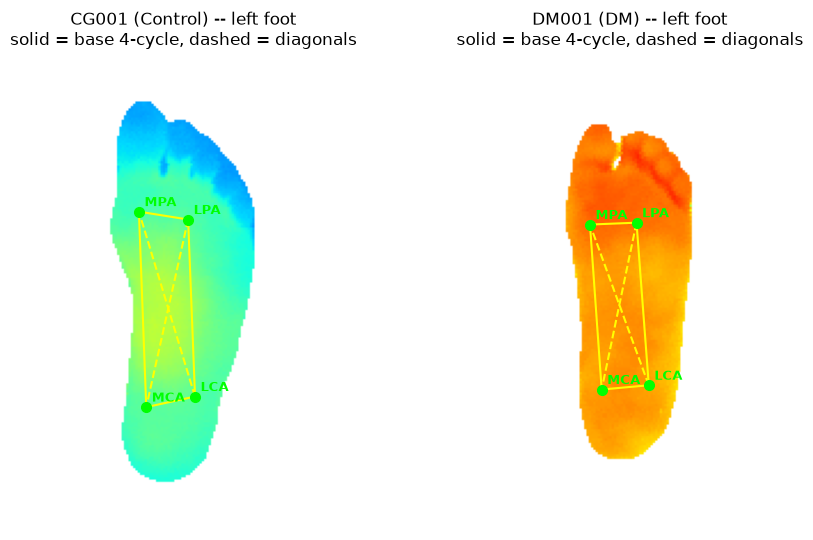

In [10]:
print("=== SECTION 8: Visual Sanity Check ===")

FOOT_SIDE_FOR_CHECK = "L"
DIAGONAL_PAIRS = {(0, 2), (2, 0), (1, 3), (3, 1)}  # for solid-vs-dashed styling below

control_subject = sorted(
    split_manifest_df.loc[split_manifest_df["group"] == "Control", "subject_id"].unique()
)[0]
dm_subject = sorted(
    split_manifest_df.loc[split_manifest_df["group"] == "DM", "subject_id"].unique()
)[0]
print(f"Control subject shown: {control_subject}")
print(f"DM subject shown:      {dm_subject}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))

for ax, subject_id, group_label in zip(axes, [control_subject, dm_subject], ["Control", "DM"]):
    key = (subject_id, FOOT_SIDE_FOR_CHECK)
    png_path = split_manifest_df.loc[
        (split_manifest_df["subject_id"] == subject_id)
        & (split_manifest_df["foot_side"] == FOOT_SIDE_FOR_CHECK),
        "colormap_png_path",
    ].values[0]
    img = np.array(Image.open(png_path))
    ax.imshow(img)

    centroids = raw_centroids_cache[key]  # (4, 2) = (row, col) in canvas-pixel frame

    # Edges: solid for base-graph, dashed for diagonal-only, drawn once per undirected pair.
    for e in range(edge_index_diag.shape[1]):
        i, j = int(edge_index_diag[0, e]), int(edge_index_diag[1, e])
        if i > j:
            continue  # skip the reverse direction of each undirected edge
        style = "--" if (i, j) in DIAGONAL_PAIRS else "-"
        ax.plot(
            [centroids[i, 1], centroids[j, 1]],
            [centroids[i, 0], centroids[j, 0]],
            style, color="yellow", linewidth=1.5, zorder=2,
        )

    # Node centroids, labeled.
    for node_idx, region in enumerate(NODE_ORDER):
        r, c = centroids[node_idx]
        ax.plot(c, r, "o", color="lime", markersize=7, zorder=3)
        ax.annotate(
            region, (c, r), color="lime", fontsize=9, fontweight="bold",
            xytext=(4, 4), textcoords="offset points", zorder=4,
        )

    ax.set_title(f"{subject_id} ({group_label}) -- left foot\nsolid = base 4-cycle, dashed = diagonals")
    ax.axis("off")

plt.tight_layout()
plt.show()


## Section 9 — Final Summary


In [11]:
print("=== SECTION 9: Final Summary ===")

n_graphs_saved = len(list(OUTPUT_DIR.glob("*.npz")))
print(f"Total graphs saved: {n_graphs_saved} (expected 334)")
if n_graphs_saved != 334:
    issues_log.append(f"SECTION 9: expected 334 .npz files on disk, found {n_graphs_saved}")

all_4_nodes = all(nf.shape[0] == 4 for nf in node_features_cache.values())
print(f"Every graph has exactly 4 nodes: {all_4_nodes}")
if not all_4_nodes:
    issues_log.append("SECTION 9: not every node_features matrix has 4 rows")

base_always_8 = edge_index_base.shape[1] == 8
diag_always_12 = edge_index_diag.shape[1] == 12
print(f"edge_index_base always has 8 directed edges: {base_always_8}")
print(f"edge_index_diag always has 12 directed edges: {diag_always_12}")
if not (base_always_8 and diag_always_12):
    issues_log.append("SECTION 9: edge_index_base/diag directed-edge counts are not fixed at 8/12")

print()
print(f"Section 5 cross-validation max absolute difference: {max_abs_diff:.10f} C "
      f"({'within' if max_abs_diff <= 0.01 else 'EXCEEDS'} the 0.01 C tolerance)")

print()
print("Base-graph topology is the anatomically-confirmed 4-cycle: LCA-LPA-MPA-MCA-LCA.")
print("The diagonal-augmented graph (4-cycle + LCA-MPA + LPA-MCA) is saved alongside it")
print("but is NOT yet chosen as the default -- this remains a deferred decision, available")
print("for a future ablation study rather than a modeling assumption baked in here.")

print()
print(f"graph_manifest.csv shape: {graph_manifest_df.shape} (expected (334, 9))")

print()
print("--- Integrity issues found across Sections 1-9 ---")
if issues_log:
    for issue in issues_log:
        print(" -", issue)
else:
    print("0 issues found.")


=== SECTION 9: Final Summary ===
Total graphs saved: 334 (expected 334)
Every graph has exactly 4 nodes: True
edge_index_base always has 8 directed edges: True
edge_index_diag always has 12 directed edges: True

Section 5 cross-validation max absolute difference: 0.0000047834 C (within the 0.01 C tolerance)

Base-graph topology is the anatomically-confirmed 4-cycle: LCA-LPA-MPA-MCA-LCA.
The diagonal-augmented graph (4-cycle + LCA-MPA + LPA-MCA) is saved alongside it
but is NOT yet chosen as the default -- this remains a deferred decision, available
for a future ablation study rather than a modeling assumption baked in here.

graph_manifest.csv shape: (334, 9) (expected (334, 9))

--- Integrity issues found across Sections 1-9 ---
0 issues found.
